# 비글루의 AI 작품 공개 전후, 무엇이 달라졌나?
2024년 7월~2026년 11월 비글루에 공개된 작품을 대상으로 공개량, 장르, 서사 태그를 비교한다. 분석 단위는 공개량에서 등록 ID 1건, 콘텐츠 특성에서 분석 대상으로 남긴 드라마 1편이다.

**실행** · 압축을 푼 뒤 `vigloo_analysis.csv`와 이 노트북이 있는 폴더에서 Jupyter로 열고 **Run All**을 누른다. Python 3, pandas, numpy, matplotlib, seaborn, IPython을 사용한다. 그림은 `results/figures`에 PNG, 분석표는 `results/tables`에 UTF-8 BOM CSV로 저장한다. 표시된 셀은 위에서부터 한 번씩 실행한다.

In [1]:
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.ticker import MaxNLocator
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Image, display

ROOT = Path.cwd()
DATA = ROOT / "vigloo_analysis.csv"
FIGURES = ROOT / "results" / "figures"
TABLES = ROOT / "results" / "tables"
for folder in (FIGURES, TABLES):
    folder.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
bundled_font = ROOT / "fonts" / "NotoSansCJKkr-Regular.otf"
if bundled_font.exists():
    font_manager.fontManager.addfont(bundled_font)
families = ["Noto Sans CJK KR", "AppleGothic", "Malgun Gothic", "NanumGothic", "Noto Sans CJK JP"]
installed = {font.name for font in font_manager.fontManager.ttflist}
font = next((name for name in families if name in installed), None)
if font is None:
    print("한글이 깨지면 압축 파일의 fonts 폴더를 노트북 옆에 두고 다시 실행하세요.")
mpl.rcParams.update({"font.family": font or "DejaVu Sans", "axes.unicode_minus": False,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.labelcolor": "#263746", "text.color": "#203443",
                     "axes.edgecolor": "#B9C4CA", "grid.color": "#E1E7EA"})
LIVE, AI = "#256278", "#CD714C"
PRE, POST = "도입 전 실사", "도입 후 실사"
GROUPS = [PRE, POST, "도입 후 AI"]
GROUP_COLORS = ["#98A8B7", LIVE, AI]

def save_table(frame, name):
    frame.to_csv(TABLES / f"{name}.csv", index=False, encoding="utf-8-sig")

def save_figure(fig, name):
    path = FIGURES / f"{name}.png"
    fig.savefig(path, dpi=165, bbox_inches="tight", pad_inches=0.22, facecolor="white")
    plt.close(fig)
    display(Image(filename=str(path), width=960))

## 1. 입력 파일과 분석 집단
중간보고서에서 정한 AI 공개 기준일은 2025년 10월 2일이다. 제작방식은 분석용 CSV에 확정한 값을 사용한다. 27편(1차 15편·추가 12편)은 팀원이 확인한 결과를 우선 적용했다. 나머지 489건은 캐스팅 기재 여부에 따른 추정이다. 추가 12편 중 〈조선 슬화핌〉은 실사 기반 AI로 확인되어 팀의 결정대로 실사에 포함했다. CSV의 `분석_처리근거`에 이 특이사항을 남겼다. 마지막 절에서는 12편 확인 전후와 〈조선 슬화핌〉의 분류에 따른 지표 차이를 점검한다. 예능·논픽션 17건과 중복 편집·후등록 2건은 콘텐츠 비교에서 제외했다. 제작방식이 달라진 애니메이션 재제작판은 콘텐츠 비교에 포함했다.

In [2]:
df = pd.read_csv(DATA, dtype={"programId": str}, keep_default_na=False, encoding="utf-8-sig")
df["releaseDate"] = pd.to_datetime(df["releaseDate"], errors="raise")
df["월"] = df["releaseDate"].dt.to_period("M")
df["집단"] = df["분석_공개시기"] + " " + df["분석_제작방식"]
assert df["programId"].is_unique
cutoff = pd.Timestamp("2025-10-02")
assert (df["releaseDate"].ge(cutoff) == df["분석_공개시기"].eq("도입 후")).all()

releases = df.loc[df["분석_공개량포함"].eq(1)].copy()
drama = df.loc[df["분석_내용비교포함"].eq(1)].copy()
verified = df.loc[df["분석_판정근거"].eq("사용자 직접 확인")].copy()
reviewed_12 = verified.loc[verified["분석_처리근거"].str.contains("추가 직접 확인", regex=False)]
hybrid_id = "15003527"
assert len(verified) == 27 and reviewed_12["분석_제작방식"].eq("실사").all()
assert reviewed_12.loc[reviewed_12["programId"].eq(hybrid_id), "title"].tolist() == ["조선 슬화핌"]
cohorts = pd.concat([x["집단"].value_counts() for x in (releases, drama)], axis=1)
cohorts.columns = ["전체 등록 건수", "장르·서사 분석 편수"]
cohorts = cohorts.reindex(GROUPS).rename_axis("집단").reset_index()
assert len(releases) == 516 and len(drama) == 497 and len(reviewed_12) == 12
display(cohorts)
save_table(cohorts, "01_분석집단")
review_log = verified.assign(확인차수=np.where(verified["programId"].isin(reviewed_12["programId"]), "2차", "1차"))
save_table(review_log.sort_values(["확인차수", "releaseDate","programId"])[
    ["확인차수", "programId", "title", "releaseDate", "url", "분석_캐스팅상태", "production_type2",
     "분석_제작방식", "분석_판정근거", "분석_처리근거"]], "02_직접확인한_27편")

,집단,전체 등록 건수,장르·서사 분석 편수
0,도입 전 실사,202,193
1,도입 후 실사,162,154
2,도입 후 AI,152,150


## 2. 월별 공개량과 월평균
등록 ID를 한 번씩 센다. 공개량에는 예능·더빙판 등 비글루가 별도로 등록한 항목도 들어 있다. 첫 관찰일인 2024년 7월 1일에는 42건이 집중됐다. 마지막 달은 2026년 11월 11일 공개분까지이므로 부분 집계로 표시한다. 월평균 비교에는 전환월을 건너뛴 같은 길이의 두 기간을 사용한다.

In [3]:
months = pd.period_range(releases["월"].min(), releases["월"].max(), freq="M")
monthly = pd.crosstab(releases["월"], releases["분석_제작방식"]).reindex(
    index=months, columns=["실사", "AI"], fill_value=0)
monthly.index.name = "월"
monthly["전체"] = monthly[["실사", "AI"]].sum(axis=1)
monthly["AI 비중(%)"] = monthly["AI"].div(monthly["전체"].replace(0, np.nan)).mul(100)
monthly["동일기간"] = "비교 제외"
monthly.loc["2024-10":"2025-09", "동일기간"] = "도입 전"
monthly.loc["2025-11":"2026-10", "동일기간"] = "도입 후"
paired = monthly.loc[monthly["동일기간"].ne("비교 제외")].copy()
period_summary = paired.groupby("동일기간", sort=False).agg(
    개월=("전체", "size"), 등록건수=("전체", "sum"), 월평균=("전체", "mean"),
    실사=("실사", "sum"), AI=("AI", "sum"), 월중앙값=("전체", "median")).reset_index()
assert period_summary["개월"].eq(12).all()
display(period_summary.round(2))
save_table(monthly.round(3).reset_index(), "03_월별_등록")
save_table(period_summary.round(3), "04_완전월_12개월_비교")

,동일기간,개월,등록건수,월평균,실사,AI,월중앙값
0,도입 전,12,124,10.33,124,0,9.5
1,도입 후,12,297,24.75,150,147,24.0


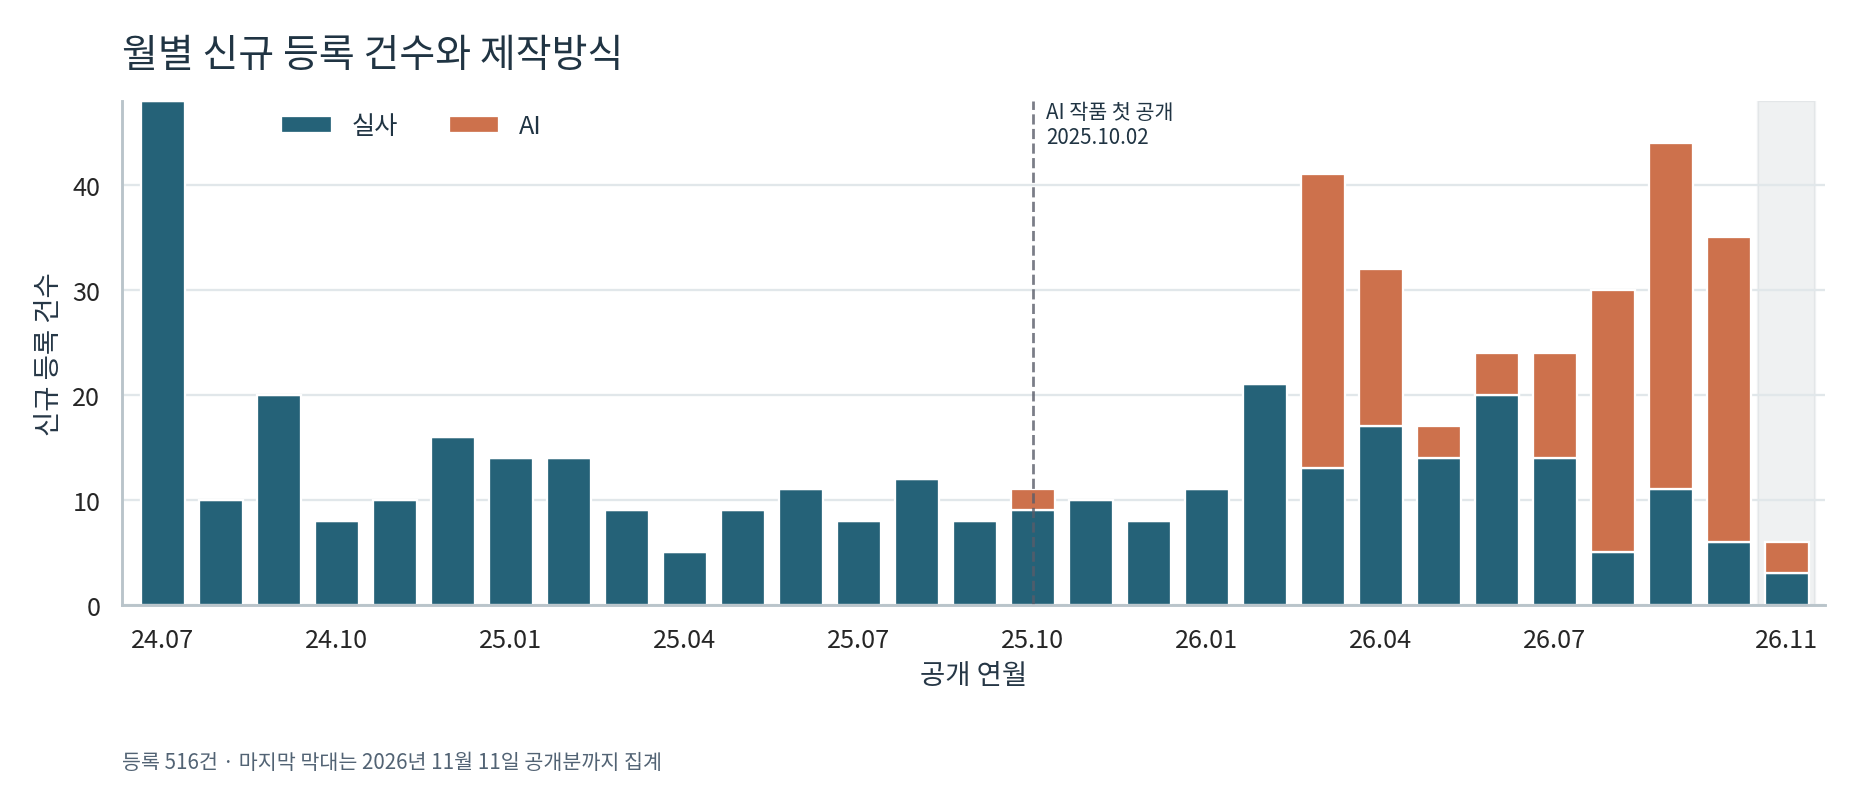

In [4]:
fig, ax = plt.subplots(figsize=(11.4, 4.7))
x = np.arange(len(monthly))
ax.bar(x, monthly["실사"], color=LIVE, width=.77, label="실사")
ax.bar(x, monthly["AI"], bottom=monthly["실사"], color=AI, width=.77, label="AI")
transition = months.get_loc(pd.Period("2025-10", freq="M"))
ax.axvline(transition, color="#595C69", linestyle="--", alpha=.8, lw=1.2)
ax.text(transition+.23, monthly["전체"].max(), "AI 작품 첫 공개\n2025.10.02", va="top", fontsize=9)
ax.axvspan(len(x)-1.49, len(x)-.52, color="#BCC3C7", alpha=.23, zorder=0)
ticks = [i for i in range(0, len(x)-2, 3)] + [len(x)-1]
ax.set_xticks(ticks, [months[i].strftime("%y.%m") for i in ticks])
ax.set(xlabel="공개 연월", ylabel="신규 등록 건수", xlim=(-.7, len(x)-.35))
ax.set_title("월별 신규 등록 건수와 제작방식", loc="left", fontsize=17, pad=15)
ax.legend(frameon=False, ncol=2, loc="upper left", bbox_to_anchor=(.08,1.02))
ax.grid(axis="x", visible=False)
fig.text(.08, .02, "등록 516건 · 마지막 막대는 2026년 11월 11일 공개분까지 집계", fontsize=9, color="#526374")
fig.subplots_adjust(bottom=.23, left=.08, right=.985, top=.88)
save_figure(fig, "01_월별_신규등록")

### 히스토그램으로 확인하는 월별 편차
막대 하나는 월별 등록 건수가 해당 구간에 들어간 달의 수다. 두 기간의 구간 너비와 축을 통일해 공개량이 일부 달에 몰렸는지 살펴본다. 왼쪽 경계는 포함하고 오른쪽 경계는 다음 구간에 넣는다(실제 관측치는 마지막 경계보다 작음).

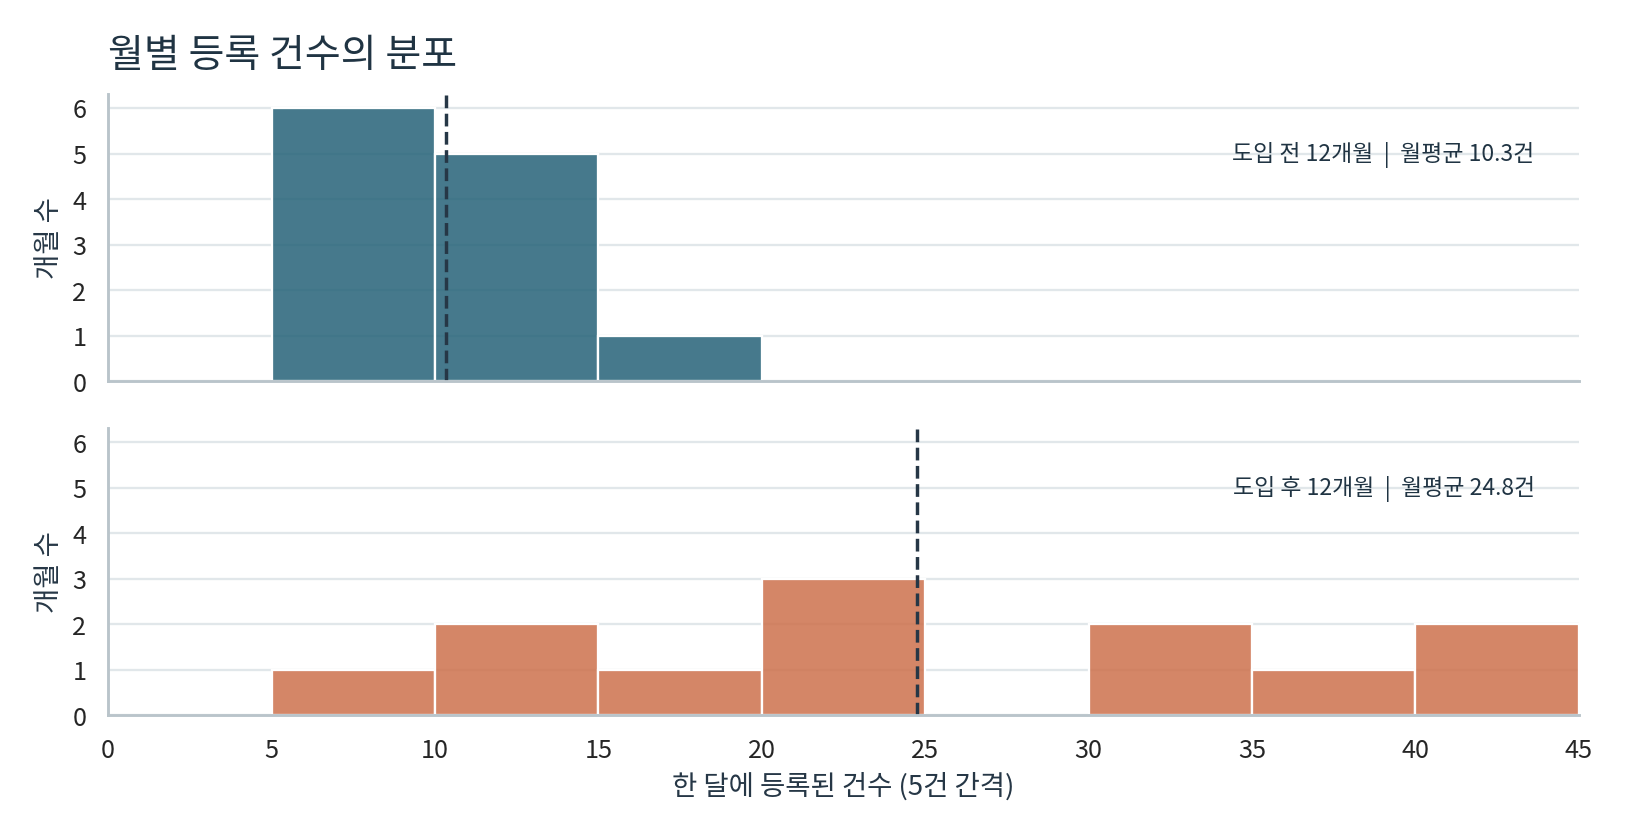

In [5]:
step = 5
bins = np.arange(0, (paired["전체"].max() // step + 2) * step, step)
fig, axes = plt.subplots(2, 1, figsize=(9.8, 5.0), sharex=True, sharey=True)
for ax, label, color in zip(axes, ["도입 전", "도입 후"], [LIVE, AI]):
    counts = paired.loc[paired["동일기간"].eq(label), "전체"]
    sns.histplot(x=counts, bins=bins, stat="count", color=color, alpha=.85,
                 edgecolor="white", ax=ax)
    ax.axvline(counts.mean(), lw=1.5, color="#263746", linestyle="--")
    ax.text(.97, .77, f"{label} 12개월  |  월평균 {counts.mean():.1f}건",
            transform=ax.transAxes, ha="right", fontsize=10)
    ax.set_ylabel("개월 수")
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    ax.grid(axis="x", visible=False)
axes[0].set_title("월별 등록 건수의 분포", loc="left", fontsize=17, pad=12)
axes[1].set(xlabel="한 달에 등록된 건수 (5건 간격)", xlim=(0, bins[-1]))
axes[1].set_xticks(bins)
fig.tight_layout()
save_figure(fig, "02_월별등록_히스토그램")

## 3. 장르 비교
두 지표를 사용한다. **장르별 작품 비율**은 해당 장르를 가진 작품 수를 집단의 전체 드라마 수로 나눈다. 한 작품에 여러 장르가 있어 이 비율을 합하면 100%를 넘을 수 있다. **상위 3개 장르 집중도**는 작품마다 1점을 주고 장르 수로 나눈 뒤 집단에서 점수가 가장 큰 세 장르의 비중을 합한다. 각 집단의 상위 세 장르는 서로 다를 수 있다. 이 지표는 소수 장르에 몰린 정도를 보여준다.

In [6]:
def long_labels(frame, prefix):
    """작품별 여러 열을 작품-라벨 한 쌍당 한 행으로 바꾼다."""
    columns = [c for c in frame.columns if c.startswith(prefix + "/")]
    long = frame.melt(id_vars=["programId", "집단"], value_vars=columns, value_name="항목")
    long["항목"] = long["항목"].str.strip()
    return long.loc[long["항목"].ne(""), ["programId", "집단", "항목"]].drop_duplicates()

def genre_tables(frame):
    labels = long_labels(frame, "genres")
    labels["가중치"] = 1 / labels.groupby("programId")["항목"].transform("size")
    totals = frame.groupby("집단")["programId"].nunique()
    assert labels["programId"].nunique() == len(frame)
    details = labels.groupby(["집단", "항목"]).agg(
        작품수=("programId", "size"), 가중합=("가중치", "sum")).reset_index()
    details["집단편수"] = details["집단"].map(totals)
    details["작품비율(%)"] = 100 * details["작품수"] / details["집단편수"]
    details["장르가중비중(%)"] = 100 * details["가중합"] / details["집단편수"]
    ranked = details.sort_values(["집단","가중합","항목"], ascending=[True,False,True])
    top = ranked.groupby("집단", sort=False).head(3).groupby("집단").agg(
        상위3장르=("항목", " / ".join), 집중도=("장르가중비중(%)","sum")).reset_index()
    return details, top

genres, concentration = genre_tables(drama)
display(concentration.set_index("집단").reindex(GROUPS).round(2))
save_table(genres.round(4), "05_장르별_작품비율과_가중비중")
save_table(concentration.round(4), "06_집단별_상위3장르")

# 도입 전후 플랫폼 전체의 집중도도 별도로 계산한다.
by_period = drama.assign(집단=drama["분석_공개시기"])
_, period_concentration = genre_tables(by_period)
display(period_concentration.round(2))
save_table(period_concentration.round(4), "07_시기별_상위3장르")

,상위3장르,집중도
집단,,
도입 전 실사,로맨스 / 드라마 / 복수·사이다,48.88
도입 후 실사,로맨스 / 재벌·신분상승 / 복수·사이다,60.06
도입 후 AI,로맨스 / 복수·사이다 / 액션·모험,45.44


,집단,상위3장르,집중도
0,도입 전,로맨스 / 드라마 / 복수·사이다,48.88
1,도입 후,로맨스 / 복수·사이다 / 재벌·신분상승,49.78


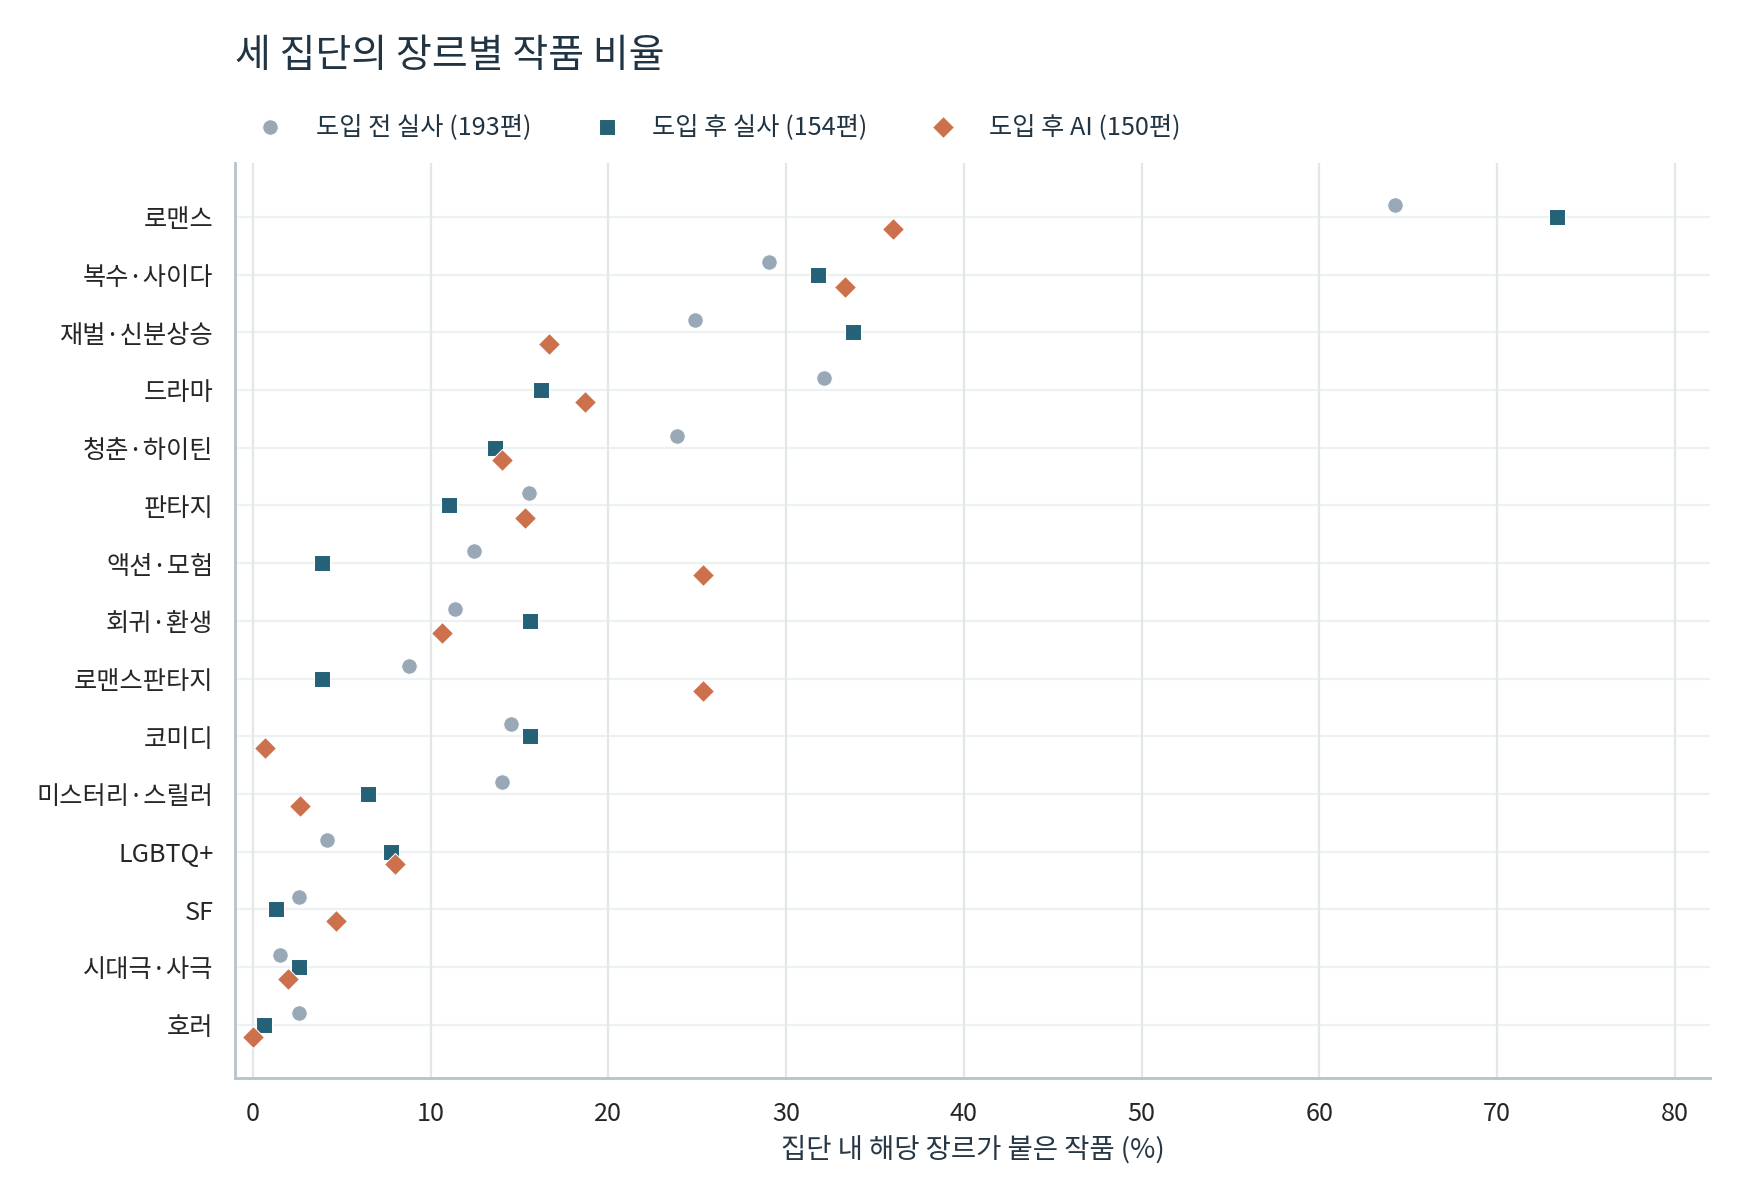

In [7]:
order = genres.groupby("항목")["작품수"].sum().sort_values(ascending=False).index
plot_genres = genres.pivot(index="항목", columns="집단", values="작품비율(%)").reindex(
    index=order, columns=GROUPS).fillna(0)
fig, ax = plt.subplots(figsize=(10.5, 7.2))
y = np.arange(len(order))
for i, group in enumerate(GROUPS):
    ax.scatter(plot_genres[group], y+(i-1)*.21, s=46, color=GROUP_COLORS[i],
               label=f"{group} ({(drama['집단']==group).sum()}편)", zorder=3,
               marker=["o","s","D"][i], edgecolor="white", linewidth=.45)
ax.set_yticks(y, order)
ax.invert_yaxis()
ax.set(xlabel="집단 내 해당 장르가 붙은 작품 (%)", ylabel="", xlim=(-1, 82))
ax.set_title("세 집단의 장르별 작품 비율", loc="left", fontsize=17, pad=42)
ax.legend(loc="lower left", bbox_to_anchor=(0,1.015), ncol=3, frameon=False, borderaxespad=0)
ax.grid(axis="y", alpha=.55)
fig.tight_layout()
save_figure(fig, "03_장르별_작품비율")

## 4. 서사 태그와 동일 장르 안의 비교
비글루가 붙인 줄거리 소재·인물 관계·배경 및 세계관 태그를 사용한다. 각 영역별로 태그가 적어도 하나 있는 작품만 분모에 넣는다. 미기재율은 별도 표로 확인한다. 작품 하나에서 같은 태그가 반복되면 한 번만 센다. 플랫폼의 ‘로판’, ‘CEO’ 등 원래 표기를 유지한다.

In [8]:
AREAS = {"줄거리 소재":"plot", "인물 관계":"relationship", "배경·세계관":"setting_worldview"}

def narrative_tables(frame):
    group_n = frame.groupby("집단").size().reindex(GROUPS)
    coverage_parts, label_parts = [], []
    for area, field in AREAS.items():
        labels = long_labels(frame, "tagsByGroup/" + field)
        tagged = labels.groupby("집단")["programId"].nunique().reindex(GROUPS, fill_value=0)
        coverage = pd.DataFrame({"집단편수":group_n, "기재편수":tagged})
        coverage["미기재편수"] = coverage["집단편수"] - coverage["기재편수"]
        coverage["기재율(%)"] = 100 * coverage["기재편수"] / coverage["집단편수"]
        coverage_parts.append(coverage.assign(영역=area).reset_index())
        items = pd.crosstab(labels["항목"], labels["집단"]).reindex(columns=GROUPS, fill_value=0)
        counts = items.rename_axis(index="항목", columns="집단").stack().rename("작품수").reset_index()
        counts["기재편수"] = counts["집단"].map(tagged)
        counts["출현율(%)"] = 100 * counts["작품수"] / counts["기재편수"].replace(0,np.nan)
        label_parts.append(counts.assign(영역=area))
    return pd.concat(coverage_parts, ignore_index=True), pd.concat(label_parts, ignore_index=True)

coverage, tags = narrative_tables(drama)
display(coverage.round(1))
save_table(coverage.round(3), "08_서사태그_기재율")
save_table(tags.round(4), "09_서사태그_전체")

,집단,집단편수,기재편수,미기재편수,기재율(%),영역
0,도입 전 실사,193,132,61,68.4,줄거리 소재
1,도입 후 실사,154,101,53,65.6,줄거리 소재
2,도입 후 AI,150,105,45,70.0,줄거리 소재
3,도입 전 실사,193,172,21,89.1,인물 관계
4,도입 후 실사,154,138,16,89.6,인물 관계
5,도입 후 AI,150,130,20,86.7,인물 관계
6,도입 전 실사,193,143,50,74.1,배경·세계관
7,도입 후 실사,154,110,44,71.4,배경·세계관
8,도입 후 AI,150,123,27,82.0,배경·세계관


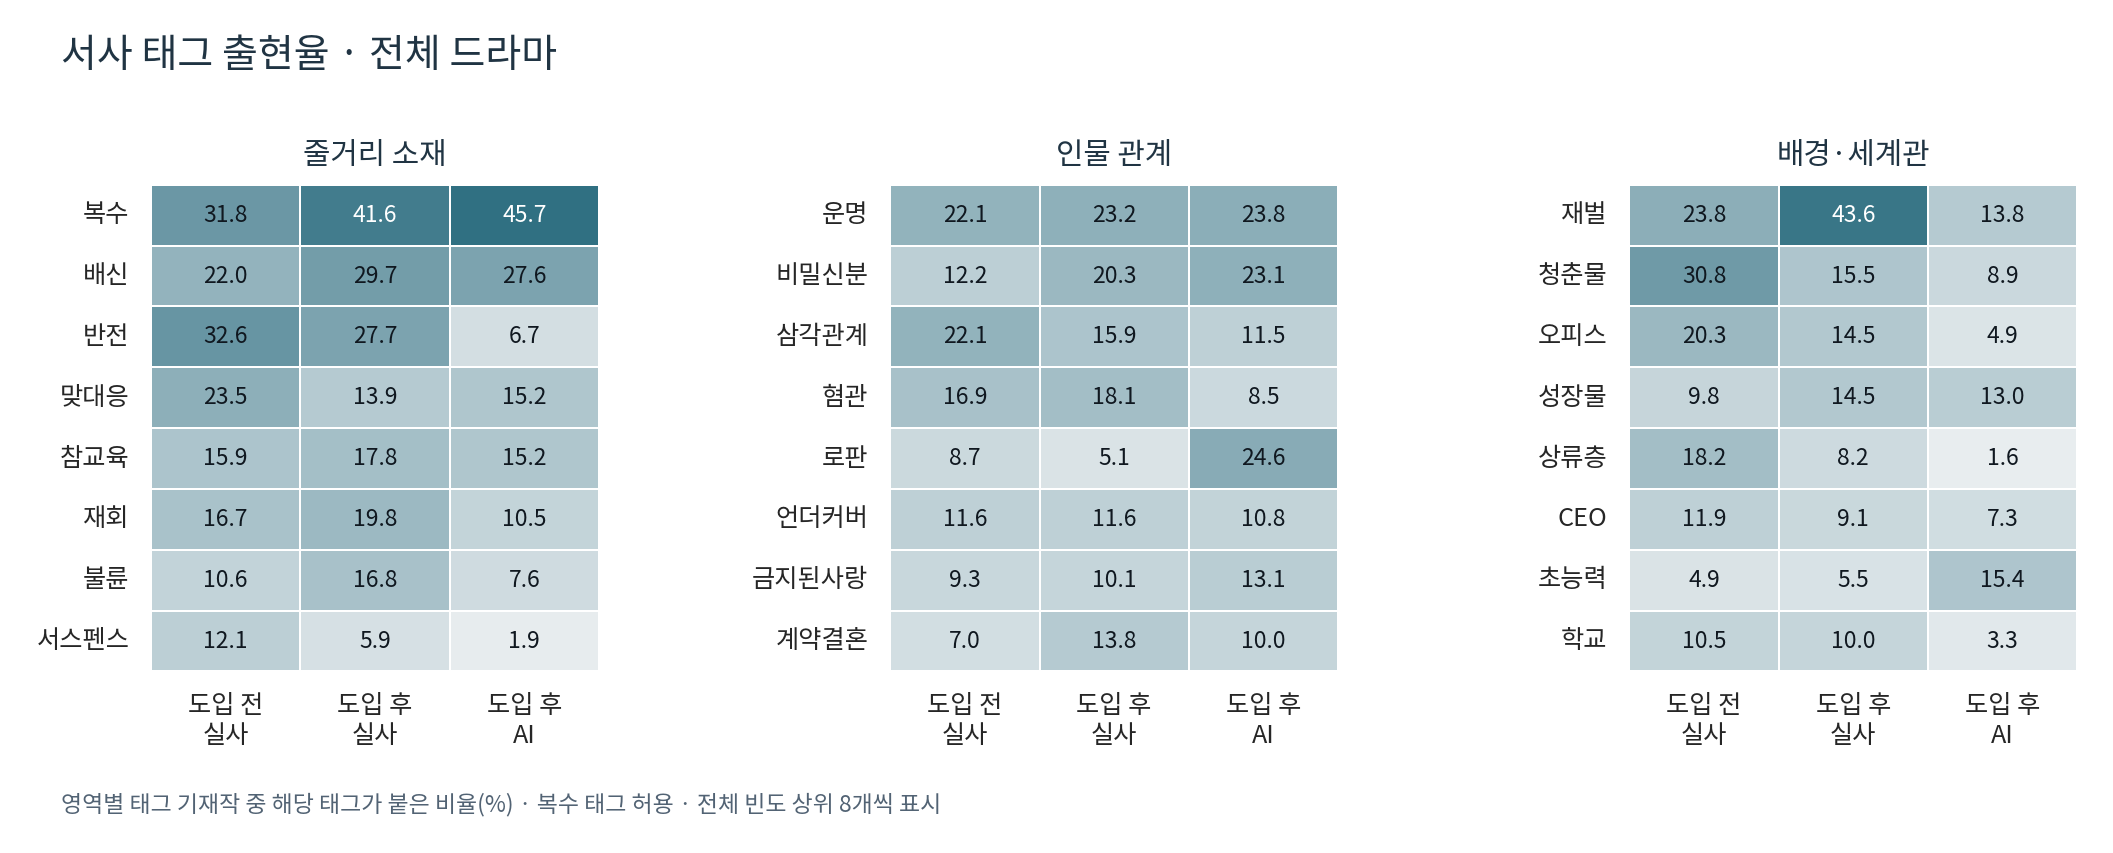

In [9]:
def draw_heatmaps(data, title, filename, top_n):
    # 모든 집단을 합한 작품 수로 행을 고른다. 세 패널은 같은 색상 범위를 쓴다.
    panels = {}
    for area in AREAS:
        subset = data.loc[data["영역"].eq(area)]
        top_items = subset.groupby("항목")["작품수"].sum().sort_values(
            ascending=False, kind="stable").head(top_n).index
        panels[area] = subset.pivot(index="항목", columns="집단", values="출현율(%)").reindex(
            index=top_items, columns=GROUPS)
    vmax = max(10, int(np.ceil(max(panel.max().max() for panel in panels.values()) / 10) * 10))
    fig, axes = plt.subplots(1, 3, figsize=(13, 5.0))
    fig.subplots_adjust(left=.087, right=.985, bottom=.21, top=.80, wspace=.65)
    for ax, (area, matrix) in zip(axes, panels.items()):
        sns.heatmap(matrix, annot=True, fmt=".1f", vmin=0, vmax=vmax, cbar=False,
                    cmap=sns.light_palette("#1F6478", as_cmap=True),
                    linewidths=.7, linecolor="white", ax=ax, annot_kws={"size":10})
        # 밝은 칸에는 진한 글씨, 어두운 칸에는 흰 글씨를 사용한다.
        palette = ax.collections[0].cmap
        for label in ax.texts:
            value = float(label.get_text())
            rgb = np.array(palette(value / vmax)[:3])
            linear = np.where(rgb <= .04045, rgb / 12.92, ((rgb + .055) / 1.055)**2.4)
            luminance = linear @ np.array([.2126, .7152, .0722])
            label.set_color("#101820" if luminance > .19 else "white")
        ax.set_title(area, fontsize=13, pad=9)
        ax.set(xlabel="", ylabel="")
        ax.set_xticklabels(["도입 전\n실사","도입 후\n실사","도입 후\nAI"], rotation=0)
        ax.tick_params(axis="y", labelrotation=0)
    fig.suptitle(title, x=.045, y=.98, ha="left", fontsize=17)
    fig.text(.045, .04, f"영역별 태그 기재작 중 해당 태그가 붙은 비율(%) · 복수 태그 허용 · 전체 빈도 상위 {top_n}개씩 표시",
             fontsize=10, color="#526374")
    save_figure(fig, filename)

draw_heatmaps(tags, "서사 태그 출현율 · 전체 드라마", "04_전체_서사태그_히트맵", 8)

,집단,집단편수,기재편수,미기재편수,기재율(%),영역
0,도입 전 실사,124,79,45,63.7,줄거리 소재
1,도입 후 실사,113,68,45,60.2,줄거리 소재
2,도입 후 AI,54,32,22,59.3,줄거리 소재
3,도입 전 실사,124,117,7,94.4,인물 관계
4,도입 후 실사,113,103,10,91.2,인물 관계
5,도입 후 AI,54,51,3,94.4,인물 관계
6,도입 전 실사,124,94,30,75.8,배경·세계관
7,도입 후 실사,113,80,33,70.8,배경·세계관
8,도입 후 AI,54,41,13,75.9,배경·세계관


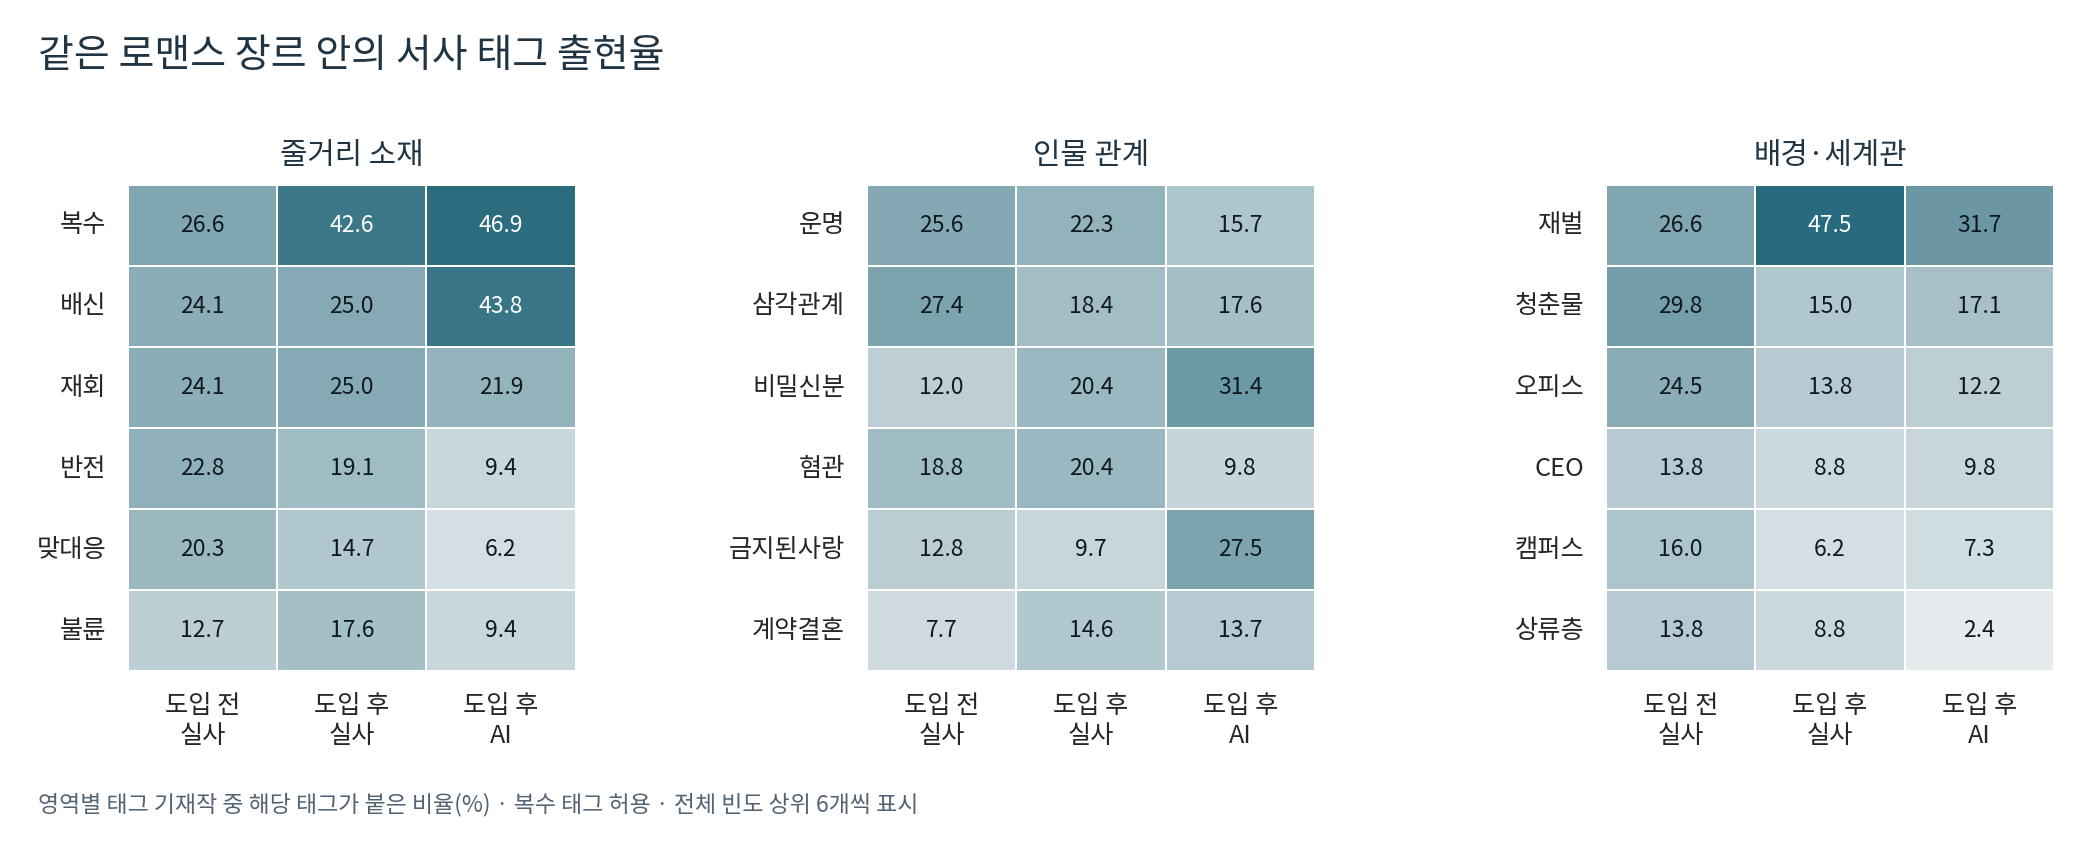

In [10]:
# 로맨스는 전체에서 가장 흔한 장르다. genres 열 중 어디에 있든 한 편으로 포함한다.
romance_ids = long_labels(drama, "genres").query("항목 == '로맨스'")["programId"]
romance = drama.loc[drama["programId"].isin(romance_ids)]
romance_coverage, romance_tags = narrative_tables(romance)
display(romance_coverage.round(1))
save_table(romance_coverage.round(3), "10_로맨스_태그기재율")
save_table(romance_tags.round(4), "11_로맨스_서사태그")
draw_heatmaps(romance_tags, "같은 로맨스 장르 안의 서사 태그 출현율", "05_로맨스_서사태그_히트맵", 6)

## 5. 분류 재검토 전후의 차이
주 분석에는 직접 확인한 12편을 모두 실사로 넣는다. 잠정 분류(12편 모두 AI)와 12편을 잠시 제외한 결과를 나란히 비교한다. 실사 기반 AI 한 편의 영향은 〈조선 슬화핌〉만 제외하는 경우로 따로 계산한다. ‘잠정’과 ‘제외’는 비교 목적의 가정이다.

,분류 기준,도입 후 실사 편수,도입 후 AI 편수,실사 집중도(%),AI 집중도(%),실사 − AI(%p)
0,직접 확인 반영,154,150,60.06,45.44,14.62
1,확인 전 잠정 분류,142,162,59.62,45.68,13.95
2,12편 제외,142,150,59.62,45.44,14.18
3,실사 기반 AI 1편만 제외,153,150,60.13,45.44,14.69


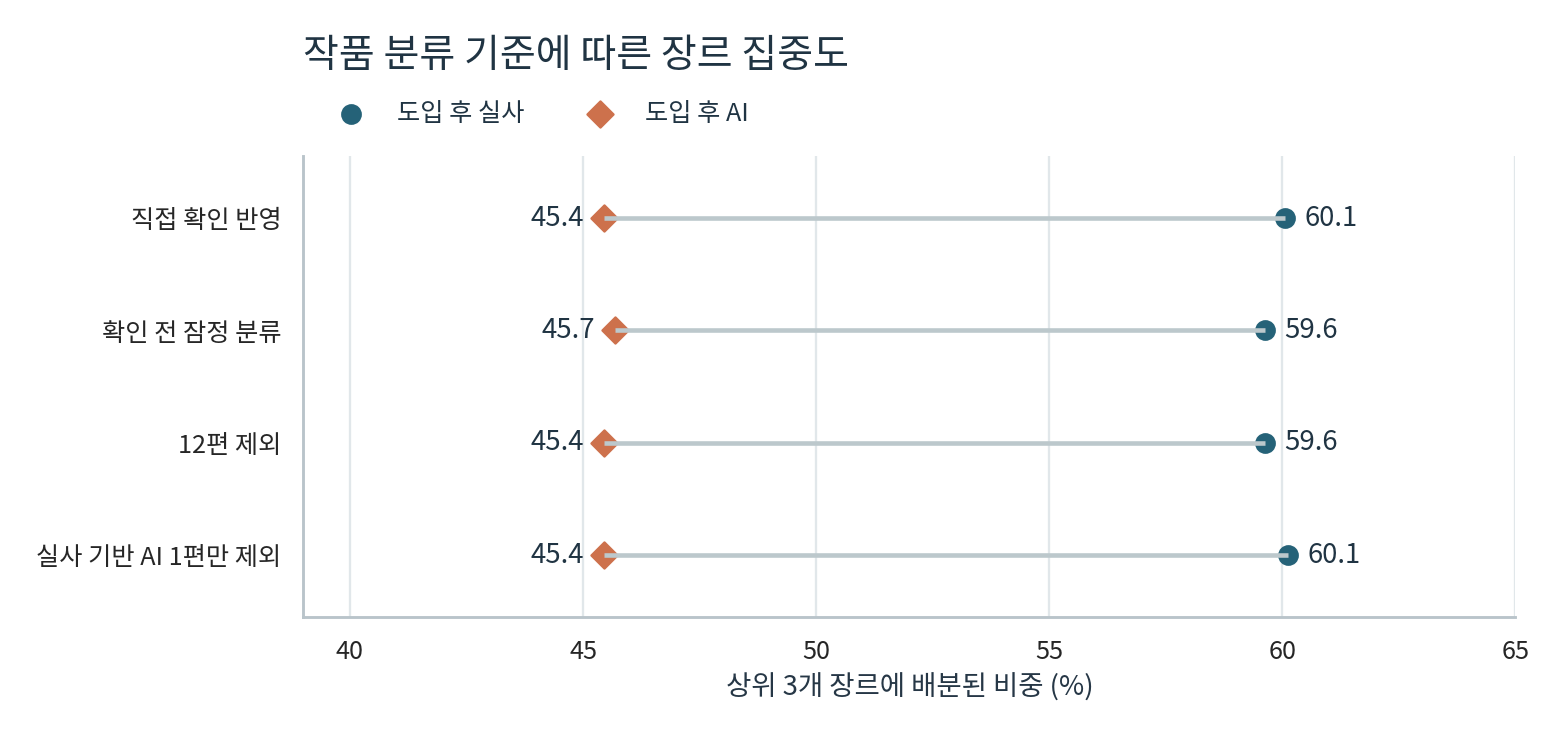

In [11]:
review_ids = set(reviewed_12["programId"])
provisional = drama.copy()
provisional.loc[provisional["programId"].isin(review_ids), "집단"] = "도입 후 AI"
cases = {
    "직접 확인 반영": drama,
    "확인 전 잠정 분류": provisional,
    "12편 제외": drama.loc[~drama["programId"].isin(review_ids)],
    "실사 기반 AI 1편만 제외": drama.loc[drama["programId"].ne(hybrid_id)],
}
comparison = []
for label, frame in cases.items():
    _, top3 = genre_tables(frame)
    metrics = top3.set_index("집단")["집중도"]
    sizes = frame["집단"].value_counts()
    comparison.append({"분류 기준": label, "도입 후 실사 편수":sizes[POST],
                       "도입 후 AI 편수":sizes["도입 후 AI"], "실사 집중도(%)":metrics[POST],
                       "AI 집중도(%)":metrics["도입 후 AI"],
                       "실사 − AI(%p)":metrics[POST]-metrics["도입 후 AI"]})
checks = pd.DataFrame(comparison)
display(checks.round(2))
save_table(checks.round(4), "12_제작방식_재분류_영향")

fig, ax = plt.subplots(figsize=(9.4, 4.4))
y = np.arange(len(checks))
for i, row in checks.iterrows():
    live, ai = row["실사 집중도(%)"], row["AI 집중도(%)"]
    ax.hlines(i, min(live, ai), max(live, ai), color="#BCC8CC", lw=2)
    ax.scatter(live, i, s=65, color=LIVE, label="도입 후 실사" if i==0 else None)
    ax.scatter(ai, i, s=65, marker="D", color=AI, label="도입 후 AI" if i==0 else None)
    ax.text(live+.42, i, f"{live:.1f}", va="center")
    ax.text(ai-.42, i, f"{ai:.1f}", va="center", ha="right")
ax.set_yticks(y, checks["분류 기준"])
ax.set_ylim(len(y)-.45,-.55)
ax.set_xlim(39,65)
ax.set_xlabel("상위 3개 장르에 배분된 비중 (%)")
ax.set_title("작품 분류 기준에 따른 장르 집중도",loc="left",fontsize=17,pad=39)
ax.legend(frameon=False,ncol=2,loc="lower left",bbox_to_anchor=(0,1.015))
ax.grid(axis="y",visible=False)
fig.tight_layout()
save_figure(fig, "06_분류기준별_장르집중도")

### 사례 확인용 작품 목록
두드러진 차이를 보인 플랫폼 태그 ‘반전’과 ‘재벌’에 대해, 도입 후 두 집단에서 각각 공개일이 가장 이른 사례를 뽑는다. 목록은 실제 줄거리와 태그의 관계를 읽기 위한 예시로, 비율 계산에는 대상 작품 전체를 사용했다.

In [12]:
examples = []
for area, item in [("줄거리 소재","반전"), ("배경·세계관","재벌")]:
    labels = long_labels(drama, "tagsByGroup/" + AREAS[area])
    ids = labels.loc[labels["항목"].eq(item), "programId"]
    matches = drama.loc[drama["programId"].isin(ids) & drama["분석_공개시기"].eq("도입 후")]
    examples.append(matches.sort_values(["releaseDate","programId"]).groupby("집단").head(1)
                    .assign(영역=area,태그=item))
examples = pd.concat(examples)[["영역","태그","집단","programId","title","releaseDate","logLine","url"]]
save_table(examples, "13_태그와_작품소개_사례")
display(examples[["태그","집단","title","logLine"]].reset_index(drop=True))

,태그,집단,title,logLine
0,반전,도입 후 실사,버디보이,"도시 소년은 시골 소년에게 알 수 없는 끌림을 느끼며, 두 사람은 점점 위험하게 깊어지는데..."
1,반전,도입 후 AI,"환생한 선제, 아내가 된 스승을 구하라",신선이던 내가 눈 떠보니 인간 쓰레기로 환생했다? 소중한 이를 지키고 정상에 다시 오르려는 한 남자의 여정
2,재벌,도입 후 AI,지옥에서 찾아온 나의 구원자,"삶에 쫓기던 민정 앞에 나타난 차가운 재벌 2세 주혁, 그의 제안은 단 하나.\n“한 달 동안 나랑 연애해요. 조건은 10억입니다.”"
3,재벌,도입 후 실사,내 첫사랑이 우리 가문의 라이벌?!,"캐벗 가문의 마지막 상속녀, 자유를 찾아 떠난 봄방학 여행에서 숙적 가문의 상속자 라이언 마셜에게 사랑에 빠진다."


## 주요 결과
- 같은 길이의 12개월 동안 공개량은 124건에서 297건으로 증가했다. 도입 후 12개월의 297건 중 실사는 150건, AI는 147건이다. 증가량 173건 중 147건은 새로 집계된 AI 작품이며, 실사 공개도 26건 늘었다.
- 상위 3개 장르 집중도는 플랫폼 전체에서 도입 전 48.9%, 도입 후 49.8%였다. 도입 후 실사에서는 60.1%, AI에서는 45.4%였다. 같은 시기의 두 제작방식 간 차이와 플랫폼 전체의 전후 차이는 별개의 결과다.
- 도입 후 전체 실사 154편 중 113편(73.4%), AI 150편 중 54편(36.0%)에 ‘로맨스’ 장르가 붙었다. 줄거리 태그 기재작에서 ‘반전’은 실사 27.7%, AI 6.7%였다. 배경·세계관 태그 기재작에서 ‘재벌’은 실사 43.6%, AI 13.8%였다. 세부 태그 비율의 분모는 해당 영역에 태그가 있는 작품 수다.
- 로맨스 안에서도 ‘반전’은 실사 19.1%, AI 9.4%였다. 비교 가능한 줄거리 태그 기재작은 각각 68편, 32편이다. 이 결과는 플랫폼의 태그 기록에 관한 기술적 비교이며 실제 서사에 등장하는 모든 장면을 세어 얻은 값은 아니다.
- 도입 후 두 제작방식의 집중도 차이는 12편 확인 전 13.9%p, 직접 확인 반영 후 14.6%p였다. 〈조선 슬화핌〉을 제외하면 14.7%p로, 이 작품 한 편의 처리에 따라 비교 방향이 바뀌지 않았다.

## 해석의 범위
분석 대상은 2026년 11월 12일 수집한 비글루 카탈로그다. 플랫폼에서 관찰한 신규 공개량은 실제 제작량·제작비와 차이가 있을 수 있다. 27편은 팀의 직접 확인을 반영했고 489건은 추정 방식에 의존한다. 태그 출현율은 플랫폼이 해당 영역의 태그를 제공한 작품에 관한 값이다. 장르 집중도는 공급된 작품 구성에 대한 지표로, 서사의 질이나 시청자 만족도는 별도 자료가 필요하다.